# 05 - Reglas simples (líneas base)

Antes de entrenar un modelo tenemos que saber **contra qué compararlo**. Si un modelo complicado no le gana a una regla que se puede hacer a mano, no sirve de nada. En este notebook probamos reglas muy simples, que no aprenden nada o casi nada, y vemos cuál es el error a superar.

Ejemplo de cómo se lee la tabla: queremos predecir la línea L, el día D, a la hora H.

| Regla | Qué predice | ¿Usa train? |
|---|---|---|
| `media_train` | El promedio de pasajeros de todas las filas de train | Sí (es un solo número) |
| `perfil_historico` | El promedio de train para esa línea, esa hora y ese tipo de día | Sí (es una tabla de promedios) |
| `ayer` | Los pasajeros de la línea L a la hora H del día anterior | No |
| `semana_pasada` | Los pasajeros de la línea L a la hora H de 7 días antes | No |
| `prom_4sem` | El promedio de 7, 14, 21 y 28 días antes, a la hora H | No |
| `mediana_4sem` | La mediana de esos mismos 4 días | No |

**La regla a superar es `mediana_4sem`.** Es la mejor de las reglas que solo miran semanas anteriores y no aprende nada de train, así que es la más fácil de explicar. La regresión del notebook 06 se compara contra ella. Igual, en la tabla de abajo se ve que `perfil_historico` le gana un poco, así que en el 06 también comparamos contra la mejor regla simple.

### Cómo medimos el error

En las fórmulas, $y$ es lo que pasó de verdad, $\hat y$ (se lee "y sombrero") es lo que predijimos y $N$ es la cantidad de filas.

| Métrica | Fórmula | Qué quiere decir |
|---|---|---|
| MAE | $\frac{1}{N}\sum \lvert \hat y - y \rvert$ | En promedio, por cuántos pasajeros le erramos en cada hora. Si da 37, le erramos por 37 pasajeros |
| RMSE | $\sqrt{\frac{1}{N}\sum (\hat y - y)^2}$ | Parecido al MAE, pero como eleva al cuadrado, los errores grandes pesan mucho más. Siempre da mayor o igual que el MAE |
| R² | $1 - \frac{\sum (\hat y - y)^2}{\sum (y - \bar y)^2}$ | Compara contra predecir siempre el promedio. 1 es perfecto, 0 es igual que el promedio, negativo es peor que el promedio |
| WAPE | $\frac{\sum \lvert \hat y - y \rvert}{\sum y}$ | El error total dividido por los pasajeros totales. 0,14 quiere decir que le erramos en el 14 % de los pasajeros |
| Sesgo | $\frac{1}{N}\sum (\hat y - y)$ | Hacia qué lado nos equivocamos. Positivo: predecimos de más. Negativo: predecimos de menos |
| Mejora | $1 - \frac{\text{MAE}}{\text{MAE de la mediana 4 sem}}$ | Cuánto menos error que la regla a superar. 0,10 es un 10 % menos de error. Negativo es peor |

**Intervalo de confianza del 95 %.** El MAE depende de qué días tocaron en validación. Para saber cuánto podría cambiar, sorteamos días al azar muchas veces (1000) y calculamos el MAE cada vez. Eso se llama **bootstrap**. El intervalo es el rango donde cae el 95 % de esos MAE. No sorteamos filas sueltas porque las filas de un mismo día se parecen mucho (mismo clima, mismo feriado), no son datos independientes. Y tampoco días sueltos, porque los días de una misma semana también se parecen (las mismas vacaciones, la misma semana de frío). Por eso sorteamos **semanas enteras** (tandas de 7 días seguidos). Así el intervalo sale un poco más ancho, pero más honesto.

**Todo se mide en validación** (todo 2025), solo con filas completas. Test (2026) no se toca.

In [0]:
%run ./00_setup

# 00 - Preparar el proyecto

Este notebook deja todo listo para que los demás funcionen. Hace cuatro cosas:

1. Le dice a Python dónde está nuestro código (la carpeta `src/bondis`), para poder escribir `from bondis import ...`.
2. Crea en Databricks el lugar donde se guardan las tablas y los archivos (`bondis_stm.datos.raw`, definido en `config.py`).
3. Crea una carpeta para cada tipo de archivo (viajes, clima, etc.).
4. Muestra cómo dividimos los datos en train, val y test.

Se puede correr todas las veces que quieras. Si algo ya existe, no lo vuelve a crear ni lo borra.

No hace falta abrirlo a mano: los otros notebooks lo corren al principio con `%run ./00_setup`.

## 1. Encontrar nuestro código

Python solo puede importar código de las carpetas que conoce. Esta celda busca la carpeta del repositorio subiendo carpeta por carpeta hasta encontrar `src/bondis`, y la agrega a la lista de carpetas que Python conoce (`sys.path`).

Código encontrado en: Trabajo-Aprendizaje-Automatico-I/src


## 2. Crear el catálogo, el esquema y el volume

Databricks ordena todo en tres niveles, como carpetas una dentro de otra:

- **Catálogo** (`bondis_stm`): la carpeta grande del proyecto.
- **Esquema** (`datos`): una subcarpeta donde van las tablas.
- **Volume** (`raw`): una carpeta para guardar archivos sueltos, como los ZIP y CSV que bajamos.


## 3. Crear una carpeta para cada tipo de archivo

| Carpeta | Qué va adentro |
|---|---|
| `viajes_zip/` | Los ZIP de viajes de cada mes, bajados a mano del portal de la Intendencia |
| `viajes/` | Los CSV de viajes, ya sacados de los ZIP |
| `clima/` | Lluvia y temperatura de cada hora |

El calendario (feriados, clases y paros) no tiene carpeta, porque está escrito a mano en `src/bondis/calendario.py`.

## 4. Revisar que todo esté bien

Muestra la versión de Spark y cuántos archivos hay en cada carpeta. Sirve para ver de un vistazo si falta subir algo.

Si este notebook lo llama otro con `%run`, solo muestra cuántos archivos hay en cada carpeta. La lista archivo por archivo y la tabla con las tablas del esquema aparecen solo cuando se corre el 00 solo. Así las salidas de los demás notebooks quedan cortas.

## 5. Cómo dividimos los datos

Usamos las fechas para dividir, no el azar, porque queremos predecir el futuro con el pasado. Un año entero para cada cosa:

| Conjunto | Fechas | Para qué se usa |
|---|---|---|
| `train` | todo 2024 | El modelo aprende con estos datos |
| `val` | todo 2025 | Comparamos y elegimos los parámetros de la regresión |
| `test` | 2026 (lo que haya) | Probamos el modelo elegido una sola vez, al final |

La fecha de fin **no** está incluida. Por eso siempre se filtra con `fecha >= inicio` y `fecha < fin`.

`train_final` es train + val juntos. Cuando ya elegimos el modelo, lo volvemos a entrenar con 2024 y 2025 antes de probarlo en 2026.

In [0]:
import importlib
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pyspark.sql import functions as F

from bondis import metricas, variables

importlib.reload(metricas)
importlib.reload(variables)

spark.conf.set("spark.sql.session.timeZone", config.TIMEZONE)
plt.rcParams.update({"figure.figsize": (13, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 200)

REFERENCIA = "mediana_4sem"

gold = variables.con_tipo_dia(spark.table(config.TABLE_GOLD)).where(F.col("fila_completa"))
train = gold.where(F.col("particion") == "train")
val = gold.where(F.col("particion") == "val")

r = val.agg(F.count("*").alias("filas"), F.countDistinct("fecha").alias("dias"),
            F.min("fecha").alias("desde"), F.max("fecha").alias("hasta")).first()
print(f"Validación: {r['filas']:,} filas, {r['dias']} días ({r['desde']} a {r['hasta']})")

Validación: 1,191,360 filas, 365 días (2025-01-01 a 2025-12-31)


## 1. Calcular las reglas que usan train

- `media_train`: un solo número, el promedio de todo train.
- `perfil_historico`: una tabla con el promedio por línea, hora y tipo de día. Si una combinación no aparece en train (por ejemplo, una línea que nunca anduvo un feriado a esa hora), se usa el promedio de esa línea a esa hora.

In [0]:
media_train = train.agg(F.avg("pasajeros")).first()[0]
perfil = train.groupBy("linea", "hora", "tipo_dia").agg(F.avg("pasajeros").alias("_perfil"))
perfil_lh = train.groupBy("linea", "hora").agg(F.avg("pasajeros").alias("_perfil_lh"))
tamanos = variables.tamano_linea(train)

val_pred = (
    val.join(perfil, ["linea", "hora", "tipo_dia"], "left")
    .join(perfil_lh, ["linea", "hora"], "left")
    .join(tamanos, "linea", "left")
    .withColumn("pred_perfil", F.coalesce("_perfil", "_perfil_lh"))
    .withColumn("pred_media", F.lit(media_train))
    .fillna({"tamano_linea": "chica"})
)

PREDICCIONES = {
    "media_train": "pred_media",
    "perfil_historico": "pred_perfil",
    "ayer": "pasajeros_lag_1d",
    "semana_pasada": "pasajeros_lag_7d",
    "prom_4sem": "pasajeros_prom_4sem",
    "mediana_4sem": "pasajeros_mediana_4sem",
}

print(f"media_train = {media_train:.1f} pasajeros por hora")
sin_perfil = val_pred.where(F.col("_perfil").isNull()).count()
print(f"Filas de val sin combinación (línea, hora, tipo de día) en train: {sin_perfil:,}")

media_train = 262.0 pasajeros por hora
Filas de val sin combinación (línea, hora, tipo de día) en train: 336


## 2. Resultados en validación

Primero se calculan unas sumas por día para las seis reglas, en una sola pasada por los datos. Todas las métricas salen de esas sumas (ver `src/bondis/metricas.py`).

In [0]:
est = metricas.estadisticos_por_dia(val_pred, "pasajeros", PREDICCIONES, grupos=["tipo_dia", "tamano_linea"])

globales = metricas.agregar_mejora(metricas.metricas(est), REFERENCIA)
intervalos = metricas.bootstrap_dias(est, REFERENCIA, n_rep=1000, seed=config.SEED, bloque=7)
globales = globales.merge(intervalos, on="modelo")
orden = list(PREDICCIONES)
globales = globales.set_index("modelo").loc[orden].reset_index()


def fmt_intervalo(v, inf, sup, dec=1, pct=False):
    f = (lambda x: f"{100 * x:.{dec}f} %") if pct else (lambda x: f"{x:,.{dec}f}")
    return f"{f(v)} [{f(inf)} a {f(sup)}]"


vista = pd.DataFrame({
    "modelo": globales["modelo"],
    "MAE [IC 95 %]": [fmt_intervalo(*x) for x in globales[["mae", "mae_inf", "mae_sup"]].to_numpy()],
    "RMSE [IC 95 %]": [fmt_intervalo(*x) for x in globales[["rmse", "rmse_inf", "rmse_sup"]].to_numpy()],
    "R²": globales["r2"].round(3),
    "WAPE": (100 * globales["wape"]).round(1).astype(str) + " %",
    "sesgo": globales["sesgo"].round(1),
    "mejora [IC 95 %]": [fmt_intervalo(*x, pct=True) for x in globales[["mejora_mae", "mejora_mae_inf", "mejora_mae_sup"]].to_numpy()],
})
print(vista.to_string(index=False))

          modelo         MAE [IC 95 %]        RMSE [IC 95 %]     R²    WAPE  sesgo               mejora [IC 95 %]
     media_train 286.2 [280.6 a 291.5] 379.1 [368.0 a 389.1] -0.001 114.4 %   11.8 -620.4 % [-728.0 % a -513.2 %]
perfil_historico    37.6 [34.1 a 41.8]    81.4 [71.5 a 92.0]  0.954  15.0 %    9.9        5.5 % [-5.8 % a 15.6 %]
            ayer    78.9 [74.5 a 83.8] 180.7 [170.5 a 192.3]  0.773  31.6 %    0.0   -98.7 % [-124.4 % a -72.3 %]
   semana_pasada    45.6 [39.9 a 52.0]  115.4 [96.6 a 133.9]  0.907  18.2 %    0.1     -14.7 % [-27.6 % a -2.0 %]
       prom_4sem    41.5 [36.9 a 47.4]  101.0 [85.8 a 118.7]  0.929  16.6 %    0.4       -4.5 % [-7.7 % a -1.2 %]
    mediana_4sem    39.7 [34.9 a 46.0]  100.9 [83.6 a 121.2]  0.929  15.9 %    5.4          0.0 % [0.0 % a 0.0 %]


**Qué vimos.**
- `media_train` da un R² de casi 0 (-0,001), como tiene que ser. Las otras reglas dan R² entre 0,77 y 0,95. Con valores tan parecidos el R² no sirve para elegir, por eso miramos el MAE y la mejora.
- La mejor regla es `perfil_historico` (MAE 37,6), seguida de `mediana_4sem` (39,7). Pero el intervalo de la mejora del perfil va de -5,8 % a 15,6 % e incluye el 0. No podemos decir que sea mejor, puede ser por los días que tocaron.
- Entre las reglas que miran para atrás, la mediana es la mejor. Le gana al promedio de 4 semanas (4,5 % menos error, intervalo de 1,2 % a 7,7 %) y a la semana pasada (14,7 %). Una semana rara mueve el promedio pero no la mediana.
- `ayer` tiene casi el doble de error que la mediana. Sin saber qué tipo de día fue ayer, el rezago de 1 día confunde (ver EDA 3.3).
- `perfil_historico` y `media_train` predicen de más (sesgo +9,9 y +11,8). En 2025 viajó menos gente que en 2024, y una regla que usa los promedios de 2024 queda alta.

**Cómo leer los intervalos.** Si el intervalo de la mejora no incluye el 0, es poco probable que la diferencia sea por los días que tocaron. Si lo incluye, no podemos decir cuál es mejor.

## 3. ¿Dónde se equivoca cada regla?

### 3.1 Por tipo de día

Lo que esperamos: las reglas que miran semanas anteriores se equivocan en los días que no se parecen a esas semanas (feriados). En cambio, `perfil_historico` se equivoca cuando cambia el nivel general (por ejemplo, cuando terminan las clases en diciembre).

In [0]:
por_tipo = metricas.agregar_mejora(metricas.metricas(est, por=["tipo_dia"]), REFERENCIA, por=["tipo_dia"])
dias_tipo = est.groupby("tipo_dia")["fecha"].nunique().rename("días")
tipos = [t for t in variables.TIPOS_DIA if t in dias_tipo.index]

print("MAE por tipo de día (pasajeros por hora):")
t = por_tipo.pivot(index="modelo", columns="tipo_dia", values="mae").loc[orden, tipos].round(1)
print(pd.concat([dias_tipo[tipos].to_frame().T, t]).to_string(), "\n")

print("Sesgo por tipo de día (> 0: se pasa):")
print(por_tipo.pivot(index="modelo", columns="tipo_dia", values="sesgo").loc[orden, tipos].round(1).to_string())

MAE por tipo de día (pasajeros por hora):
tipo_dia          hábil  sábado  domingo  turismo  feriado
días              249.0    50.0     51.0      7.0      8.0
media_train       315.6   232.2    211.6    235.6    227.7
perfil_historico   42.0    26.1     23.2     49.7     51.7
ayer               69.1   134.7     68.1     43.0    136.7
semana_pasada      45.9    30.5     27.5    126.5    174.0
prom_4sem          41.2    25.7     23.0    122.5    198.7
mediana_4sem       38.5    25.2     21.6    122.9    211.6 

Sesgo por tipo de día (> 0: se pasa):
tipo_dia          hábil  sábado  domingo  turismo  feriado
modelo                                                    
media_train       -39.3    86.1    148.4     99.2    190.9
perfil_historico   11.2     8.3      7.0      3.4      6.5
ayer              -41.4   125.0     60.9      3.2    117.9
semana_pasada      -8.3    -2.1     -0.3    122.8    172.8
prom_4sem          -8.7    -1.9      0.0    119.1    197.8
mediana_4sem       -1.9    -0.3  

**Qué vimos.** Las reglas que miran semanas anteriores andan bien en días comunes (la mediana da 38,5 en hábiles, 25,2 en sábados y 21,6 en domingos) y muy mal en feriados (212) y en Turismo (123), donde siempre predicen de más. El perfil es al revés: es peor en días comunes (42,0 en hábiles), pero mucho mejor en feriados (51,7) y en Turismo (49,7), porque usa el promedio de los feriados y del Turismo de 2024.

Las dos reglas se equivocan en días distintos, así que conviene combinarlas: la mediana en días comunes y el perfil en feriados y Turismo. Esa es la regla `regla_por_tipo_dia` del notebook 06.

### 3.2 Por tamaño de línea

Separamos las líneas según cuántos pasajeros llevaron en train: las 20 más grandes, las 30 que siguen y el resto. En las líneas grandes los errores son más grandes en pasajeros (ver EDA, sección 4), así que el MAE total lo deciden ellas. El WAPE, como es un porcentaje, sirve para comparar grupos de distinto tamaño.

In [0]:
por_tam = metricas.metricas(est, por=["tamano_linea"])
grupos_tam = [g for g in ["grande", "mediana", "chica"] if g in set(por_tam["tamano_linea"])]
for col, titulo in (("mae", "MAE"), ("wape", "WAPE")):
    t = por_tam.pivot(index="modelo", columns="tamano_linea", values=col).loc[orden, grupos_tam]
    print(f"{titulo} por tamaño de línea:")
    print((t * 100).round(1).astype(str).add(" %").to_string() if col == "wape" else t.round(1).to_string(), "\n")

MAE por tamaño de línea:
tamano_linea      grande  mediana  chica
modelo                                  
media_train        547.9    323.8  212.2
perfil_historico    93.0     63.5   15.6
ayer               195.1    139.1   31.0
semana_pasada      111.8     77.5   19.1
prom_4sem          103.2     71.2   16.8
mediana_4sem        97.8     68.0   16.4 

WAPE por tamaño de línea:
tamano_linea      grande mediana    chica
modelo                                   
media_train       77.5 %  73.3 %  275.0 %
perfil_historico  13.2 %  14.4 %   20.3 %
ayer              27.6 %  31.5 %   40.1 %
semana_pasada     15.8 %  17.5 %   24.7 %
prom_4sem         14.6 %  16.1 %   21.8 %
mediana_4sem      13.8 %  15.4 %   21.2 % 



**Qué vimos.** En pasajeros, el error de las líneas grandes es 6 veces el de las chicas (97,8 contra 16,4 con la mediana). En porcentaje es al revés: las chicas tienen más error relativo (WAPE de 21 % contra 14 %), porque con pocos pasajeros cualquier diferencia pesa más. El orden de las reglas es el mismo en los tres grupos.

### 3.3 Día por día

El MAE de cada día de validación para tres reglas. Los picos son los días en que la regla se equivoca mucho. Tendrían que coincidir con días especiales (líneas grises punteadas) o con cambios en las clases (líneas rojas: el primer día en que empiezan o terminan las clases de escuela o liceo).

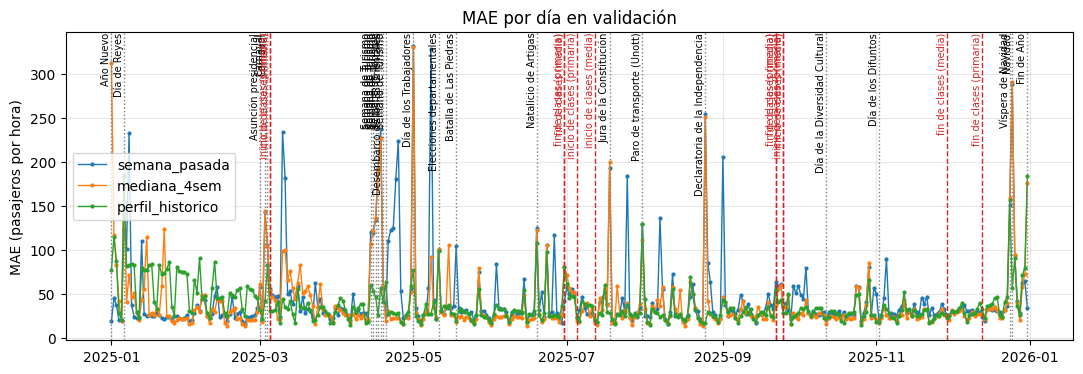

Los 10 días con más error de mediana_4sem:
     fecha tipo_dia              nombre_dia_especial  clases_primaria  clases_media   mae  sesgo
2025-05-01  feriado          Día de los Trabajadores             True          True 330.3  330.3
2025-01-01  feriado                        Año Nuevo            False         False 311.5  311.5
2025-12-25  feriado                          Navidad            False         False 290.1  290.1
2025-08-25  feriado Declaratoria de la Independencia             True          True 250.9  249.0
2025-04-18  turismo                Semana de Turismo             True          True 226.6  225.8
2025-07-18  feriado          Jura de la Constitución             True          True 200.3  198.8
2025-04-17  turismo                Semana de Turismo             True          True 190.8  189.3
2025-12-31    hábil                       Fin de Año            False         False 176.5  175.4
2025-01-06    hábil                     Día de Reyes            False         False 

In [0]:
info_dias = (val.select("fecha", "tipo_dia", "nombre_dia_especial", "clases_primaria", "clases_media")
             .distinct().toPandas())
info_dias["fecha"] = pd.to_datetime(info_dias["fecha"])

diario = metricas.metricas(est, por=["fecha"])
fig, ax = plt.subplots()
for m in ["semana_pasada", "mediana_4sem", "perfil_historico"]:
    s = diario[diario["modelo"] == m].sort_values("fecha")
    ax.plot(s["fecha"], s["mae"], marker=".", ms=4, lw=1, label=m)
tope = ax.get_ylim()[1]
for _, d in info_dias.dropna(subset=["nombre_dia_especial"]).iterrows():
    ax.axvline(d["fecha"], color="gray", ls=":", lw=1)
    ax.text(d["fecha"], tope, d["nombre_dia_especial"], rotation=90, va="top", ha="right", fontsize=7)

# Días en que empiezan o terminan las clases (clases_primaria o clases_media cambia respecto del día anterior)
cal = info_dias.sort_values("fecha").set_index("fecha")[["clases_primaria", "clases_media"]]
for nivel in ("primaria", "media"):
    c = cal[f"clases_{nivel}"].astype(int).diff()
    for f, v in c[c != 0].dropna().items():
        etiqueta = f"{'inicio' if v > 0 else 'fin'} de clases ({nivel})"
        ax.axvline(f, color="tab:red", ls="--", lw=1)
        ax.text(f, tope, etiqueta, rotation=90, va="top", ha="right", fontsize=7, color="tab:red")

ax.set(title="MAE por día en validación", ylabel="MAE (pasajeros por hora)")
ax.legend(loc="center left")
plt.show()

peores = (diario[diario["modelo"] == REFERENCIA].nlargest(10, "mae")
          .merge(info_dias, on="fecha")[["fecha", "tipo_dia", "nombre_dia_especial", "clases_primaria",
                                         "clases_media", "mae", "sesgo"]])
print(f"Los 10 días con más error de {REFERENCIA}:")
print(peores.round(1).to_string(index=False))

**Qué vimos.** Los 10 peores días de la mediana son todos días especiales: los dos días casi sin ómnibus (1° de mayo y 1° de enero), Navidad, los feriados del 25 de agosto y el 18 de julio, el jueves y el viernes de Turismo, y el 6 de enero, el 24 y el 31 de diciembre. En todos el sesgo es positivo: la mediana predice de más porque las semanas anteriores fueron normales.

Todos se saben de antemano con el calendario, así que un modelo que lo use tendría que poder mejorar justo ahí.

## 4. Guardar los resultados

Los resultados se guardan en la tabla `resultados_modelos` con `etapa = 'baseline'`. El notebook 06 agrega los suyos con otra etapa, así comparamos todo desde una sola tabla. Si se vuelve a correr este notebook, se reemplazan solo las filas de `baseline`.

In [0]:
ETAPA = "baseline"
salida = globales.assign(etapa=ETAPA, conjunto="val", referencia=REFERENCIA,
                         fecha_ejecucion=datetime.now().strftime("%Y-%m-%d %H:%M"))
columnas = ["etapa", "conjunto", "modelo", "referencia", "filas", "mae", "mae_inf", "mae_sup", "rmse",
            "rmse_inf", "rmse_sup", "r2", "wape", "sesgo", "mejora_mae", "mejora_mae_inf", "mejora_mae_sup",
            "fecha_ejecucion"]
salida = salida[columnas].astype({c: "float64" for c in columnas if c not in
                                  ("etapa", "conjunto", "modelo", "referencia", "fecha_ejecucion", "filas")})

escritor = spark.createDataFrame(salida).write.format("delta").mode("overwrite").option("mergeSchema", "true")
if spark.catalog.tableExists(config.TABLE_RESULTADOS):
    escritor.option("replaceWhere", f"etapa = '{ETAPA}'").saveAsTable(config.TABLE_RESULTADOS)
else:
    escritor.saveAsTable(config.TABLE_RESULTADOS)

print(spark.table(config.TABLE_RESULTADOS).where(F.col("etapa") == ETAPA)
      .select("modelo", "mae", "rmse", "r2", "mejora_mae").toPandas().round(3).to_string(index=False))

          modelo     mae    rmse     r2  mejora_mae
     media_train 286.196 379.132 -0.001      -6.204
perfil_historico  37.560  81.402  0.954       0.055
            ayer  78.949 180.683  0.773      -0.987
   semana_pasada  45.588 115.371  0.907      -0.147
       prom_4sem  41.523 101.039  0.929      -0.045
    mediana_4sem  39.730 100.903  0.929       0.000
